# ARGus — CD-HIT al 99.5 % con cobertura 95 %

Tercera configuración del agrupamiento. Cambia **solo** lo que se pidió en la reunión:

```
antes:   -c 0.99   -aS 0.90  -aL 0.90  -n 10
ahora:   -c 0.995  -aS 0.95  -aL 0.95  -n 10
```

El resto de los parámetros queda idéntico, incluido `-n`. El manual de CD-HIT
recomienda palabra de 10 u 11 para umbrales entre 0.95 y 1.0, así que 10 sigue siendo
válido a 0.995 y mantenerlo deja una variable menos cambiada entre las dos corridas.

Subir la identidad **y** la cobertura hace el agrupamiento más estricto por dos vías a
la vez: dos secuencias ahora tienen que parecerse más y además alinearse a lo largo de
casi toda su longitud para considerarse la misma. Se esperan más representantes que los
6,257 del 99 %.

---

### Orden del cuaderno

| sección | qué hace | cuánto tarda |
|---|---|---|
| 1 | CD-HIT a 0.995 | minutos |
| 2 | actualizar el conjunto de positivos | segundos |
| 3 | etapa 2 — censo de familias y RandomForest | segundos |
| 4 | etapa 1 — modelo binario | ~1 min |
| 5 | control de contaminación | segundos |
| 6 | calibración del umbral | segundos |
| 7 | comparación de las tres configuraciones | segundos |
| 8 | etapa 2 con DNABERT *(opcional)* | ~30 min en CPU |

Se puede correr de arriba abajo. La sección 8 es la única lenta y está al final a
propósito, para que se pueda dejar fuera en una primera pasada.

> **Antes de empezar**: debe existir `respaldo_id99/` con el estado anterior. Este
> cuaderno sobrescribe `data/processed/argdb_POSITIVO_final.fasta` y los modelos.

---

## 0. Preparación

In [2]:
import json, re, shutil, subprocess, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'results').is_dir())
RES, INTER, PROC = RAIZ / 'results', RAIZ / 'data' / 'interim', RAIZ / 'data' / 'processed'
MOD, APP = RAIZ / 'data' / 'models', RAIZ / 'app'
ID = '995'

plt.rcParams.update({'font.size': 9, 'axes.linewidth': 0.8, 'figure.dpi': 110})
ESTILOS = ['-', '--', '-.', ':']

def correr(cmd, mostrar=True, cola=None):
    """Ejecuta un comando en la raíz del proyecto y devuelve su salida."""
    t0 = time.time()
    r = subprocess.run(cmd, cwd=RAIZ, capture_output=True, text=True)
    s = r.stdout + (('\n' + r.stderr) if r.returncode else '')
    if mostrar:
        print(s if cola is None else '\n'.join(s.splitlines()[-cola:]))
    print(f'[{time.time()-t0:.0f} s, código {r.returncode}]')
    return s

def contar(p):
    p = Path(p)
    if not p.exists():
        return None
    with open(p, encoding='utf-8', errors='replace') as f:
        return sum(1 for l in f if l.startswith('>'))

def leer_json(p):
    p = Path(p)
    return json.load(open(p, encoding='utf-8')) if p.exists() else {}

print('proyecto:', RAIZ)
resp = RAIZ / 'respaldo_id99'
print('respaldo del 99 %:', 'ok' if resp.is_dir() else 'NO EXISTE — detente y créalo antes de seguir')
if resp.is_dir():
    for f in sorted(resp.iterdir()):
        print(f'   {f.name}')

proyecto: /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias
respaldo del 99 %: ok
   argdb_POSITIVO_final.fasta
   argus_rf_k6_id99_v2.joblib
   combinado_v4_reducido_id99.fasta
   dnabert6_familias_cabeza.pt
   etiquetas_finales.tsv
   familias_card.tsv
   familias_dnabert_meta.json
   modelo_familias.joblib
   modelo_familias_meta.json


## 1. CD-HIT al 99.5 % con cobertura 95 %

`-aS` y `-aL` exigen que el alineamiento cubra al menos ese porcentaje de la secuencia
más corta y de la más larga respectivamente. Juntas impiden que un fragmento parcial se
absorba dentro de un gen completo solo porque coincide en el trozo que comparten.

In [3]:
ENTRADA  = INTER / 'combinado_v4_pre_cdhit.fasta'
SALIDA   = INTER / f'combinado_v4_reducido_id{ID}.fasta'

print(f'entrada: {contar(ENTRADA):,} secuencias')

cmd = ['cd-hit-est',
       '-i', str(ENTRADA),
       '-o', str(SALIDA),
       '-c', '0.995', '-aS', '0.95', '-aL', '0.95',
       '-n', '10', '-d', '0', '-M', '6000', '-T', '10']
print(' '.join(cmd), '\n')
_ = correr(cmd, cola=12)

entrada: 30,912 secuencias
cd-hit-est -i /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim/combinado_v4_pre_cdhit.fasta -o /mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/interim/combinado_v4_reducido_id995.fasta -c 0.995 -aS 0.95 -aL 0.95 -n 10 -d 0 -M 6000 -T 10 


# comparing sequences from      29952  to      30912
.................---------- new table with      358 representatives

    30912  finished       7933  clusters

Approximated maximum memory consumption: 221M
writing new database
writing clustering information
program completed !

Total CPU time 27.56
[7 s, código 0]


In [4]:
n_pre  = contar(ENTRADA)
n_995  = contar(SALIDA)
n_99   = contar(INTER / 'combinado_v4_reducido_id99.fasta')
n_95   = contar(INTER / 'combinado_v4_reducido.fasta')

tabla = pd.DataFrame([
    {'configuración': '95 %  (-aS/-aL 0.90)', 'representantes': n_95},
    {'configuración': '99 %  (-aS/-aL 0.90)', 'representantes': n_99},
    {'configuración': '99.5 % (-aS/-aL 0.95)', 'representantes': n_995},
]).set_index('configuración')
tabla['% del total'] = (tabla['representantes'] / n_pre * 100).round(1)
print(f'partiendo de {n_pre:,} secuencias\n')
tabla

partiendo de 30,912 secuencias



,representantes,% del total
configuración,,
95 % (-aS/-aL 0.90),4228,13.7
99 % (-aS/-aL 0.90),6257,20.2
99.5 % (-aS/-aL 0.95),7933,25.7


In [26]:
meta = leer_json(RES / 'familias' / 'modelo_familias_meta.json')

etq = pd.read_csv(RES / 'familias' / 'etiquetas_finales.tsv', sep='\t')
col = next((c for c in etq.columns if c.lower() in
            ('grupo', 'familia', 'etiqueta', 'clase')), etq.columns[-1])
cuenta = etq[col].value_counts()

# el censo anterior, para ver qué creció
ant = pd.read_csv(RAIZ / 'respaldo_id99' / 'etiquetas_finales.tsv', sep='\t')
cant = ant[next((c for c in ant.columns if c.lower() in
                 ('grupo', 'familia', 'etiqueta', 'clase')), ant.columns[-1])].value_counts()

tabla = pd.DataFrame({
    'id99':  [int(cant.get(f, 0)) for f in cuenta.index],
    'id995': cuenta.values,
}, index=cuenta.index)
tabla['cambio'] = tabla['id995'] - tabla['id99']
tabla['% del total'] = (tabla['id995'] / cuenta.sum() * 100).round(1)
tabla.index.name = 'familia'

print(f"min_clase usado : {meta.get('min_clase')}")
print(f"familias        : {len(cuenta)}")
print(f"genes           : {int(cuenta.sum()):,}")
print(f"antes (99 %)    : {len(cant)} familias, {int(cant.sum()):,} genes\n")
tabla

min_clase usado : 30
familias        : 30
genes           : 2,917
antes (99 %)    : 30 familias, 2,116 genes



,id99,id995,cambio,% del total
familia,,,,
otras beta-lactamasas,519,760,241,26.1
OXA beta-lactamasa,411,612,201,21.0
cefalosporinasa AmpC (ADC/ACT/CMY),247,419,172,14.4
beta-lactamasa de espectro extendido,39,121,82,4.1
eflujo MFS,99,102,3,3.5
carbapenemasa (IMP/VIM/NDM/KPC),57,101,44,3.5
eflujo RND,80,82,2,2.8
AAC acetiltransferasa,69,78,9,2.7
van / glucopéptidos,77,78,1,2.7


In [29]:
def por_base(p):
    """Cuenta secuencias por base de origen, leyendo el prefijo del encabezado."""
    p = Path(p)
    if not p.exists():
        print(f'[falta] {p}')
        return None
    c = {}
    with open(p, encoding='utf-8', errors='replace') as f:
        for l in f:
            if l.startswith('>'):
                h = l[1:].strip()
                base = h.split('|')[0].split()[0] if '|' in h else '(sin base)'
                c[base] = c.get(base, 0) + 1
    return pd.Series(c)

FUENTES = [
    ('95 %',   INTER / 'combinado_v4_reducido.fasta'),
    ('99 %',   INTER / 'combinado_v4_reducido_id99.fasta'),
    ('99.5 %', INTER / f'combinado_v4_reducido_id{ID}.fasta'),
]
cols = {e: s for e, p in FUENTES if (s := por_base(p)) is not None}

t = pd.DataFrame(cols).fillna(0).astype(int)
t = t.sort_values(t.columns[-1], ascending=False)
t.loc['TOTAL'] = t.sum()

if '99 %' in t.columns and '99.5 %' in t.columns:
    t['cambio'] = (t['99.5 %'] - t['99 %']).map(lambda v: f'{v:+,}')
    t['factor'] = (t['99.5 %'] / t['99 %'].replace(0, np.nan)).map(
        lambda v: '—' if pd.isna(v) else f'{v:.2f}x')
t.index.name = 'base'
t

,95 %,99 %,99.5 %,cambio,factor
base,,,,,
CARD,1380,2208,3009,+801,1.36x
ResFinderFG,2005,2555,2870,+315,1.12x
MEGARes,459,773,1024,+251,1.32x
AMRFinderPlus,197,414,600,+186,1.45x
ResFinder,157,278,400,+122,1.44x
ARGANNOT,30,29,30,+1,1.03x
TOTAL,4228,6257,7933,"+1,676",1.27x


In [30]:
s = correr([sys.executable, 'scripts/modelo_familias.py',
            '--solo-censo', '--sin-otras', '--min-clase', '30'], mostrar=False)
i = s.find('CENSO DESPUÉS DE AGRUPAR')
print(s[i:s.find('ETIQUETAS FINALES', i)])

[2 s, código 0]
CENSO DESPUÉS DE AGRUPAR
  grupo                                           n       %   70/15/15
  otras beta-lactamasas                         760  25.26%   532/114/114
  OXA beta-lactamasa                            612  20.34%   428/92/92
  cefalosporinasa AmpC (ADC/ACT/CMY)            419  13.92%   293/63/63
  beta-lactamasa de espectro extendido          121   4.02%   85/18/18
  eflujo MFS                                    102   3.39%   71/15/16
  carbapenemasa (IMP/VIM/NDM/KPC)               101   3.36%   71/15/15
  eflujo RND                                     82   2.73%   57/12/13
  AAC acetiltransferasa                          78   2.59%   55/12/11
  van / glucopéptidos                            78   2.59%   55/12/11
  qnr quinolonas                                 77   2.56%   54/12/11
  Erm metiltransferasa 23S                       60   1.99%   42/9/9
  dfr dihidrofolato reductasa                    56   1.86%   39/8/9
  MCR fosfoetanolamina transferasa 

Más representantes significa que CD-HIT colapsó menos secuencias, no que haya datos
nuevos. Son los mismos genes de partida, agrupados con un criterio más fino.

## 2. Actualizar el conjunto de positivos

El resto del sistema lee `data/processed/argdb_POSITIVO_final.fasta`. En las corridas
anteriores ese archivo era una copia literal de la salida de CD-HIT, así que se mantiene
el mismo procedimiento.

In [5]:
DESTINO = PROC / 'argdb_POSITIVO_final.fasta'
shutil.copy2(SALIDA, DESTINO)

assert contar(DESTINO) == n_995, 'la copia no coincide con la salida de CD-HIT'
print(f'{DESTINO}  ->  {contar(DESTINO):,} secuencias')
print(f'negativos (sin cambios): {contar(PROC / "argdb_NEGATIVO_final.fasta"):,}')

/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/data/processed/argdb_POSITIVO_final.fasta  ->  7,933 secuencias
negativos (sin cambios): 26,513


## 3. Etapa 2 — familias

Primero se recalculan las familias de CARD sobre el conjunto nuevo, después el censo con
los dos mínimos (50 y 30) para poder separar lo que aportan los datos de lo que aporta
relajar el criterio, y al final se entrena el RandomForest.

In [6]:
print('--- familias_card.py ---')
_ = correr([sys.executable, 'scripts/familias_card.py'], cola=25)

--- familias_card.py ---
  con etiqueta: 3,009 de 3,009 (100.0 %)  |  10 con varias etiquetas (';')
  clases distintas: 7  |  con >= 50: 5  |  con < 7: 1
  secuencias en clases usables: 3,006
  desbalance entre usables: 2,320 vs 66 (razón 35.2x)

  clase                                                 n       %   70/15/15
  antibiotic inactivation                           2,320  77.10%   1624/348/348
  antibiotic efflux                                   268   8.91%   188/40/40
  antibiotic target alteration                        216   7.18%   151/32/33
  antibiotic target protection                        136   4.52%   95/20/21
  antibiotic target replacement                        66   2.19%   46/10/10
  reduced permeability to antibiotic                   12   0.40%   8/2/2  <- pocos
  resistance by host-dependent nutrient acquisitio      1   0.03%   1/0/0  <- IMPOSIBLE

CHEQUEO DE CONFUNDIDO: familia x base de origen
  Universo de una sola base: no aplica (no hay confundido posibl

In [7]:
def censo(min_clase):
    s = correr([sys.executable, 'scripts/modelo_familias.py',
                '--solo-censo', '--sin-otras', '--min-clase', str(min_clase)],
               mostrar=False)
    m = re.search(r'grupos con >= \d+:\s*(\d+)\s*\(([\d,]+) genes\)', s)
    return (int(m.group(1)), int(m.group(2).replace(',', ''))) if m else (None, None)

# el de 50 primero: el de 30 se corre al final para dejar etiquetas_finales.tsv correcto
n50, g50 = censo(50)
n30, g30 = censo(30)
print(f'min_clase 50 -> {n50} familias, {g50:,} genes')
print(f'min_clase 30 -> {n30} familias, {g30:,} genes')

[1 s, código 0]
[2 s, código 0]
min_clase 50 -> 12 familias, 2,546 genes
min_clase 30 -> 17 familias, 2,727 genes


In [8]:
print('--- entrenamiento del RandomForest de familias ---')
salida_fam = correr([sys.executable, 'scripts/modelo_familias.py',
                     '--min-clase', '30', '--sin-otras'], mostrar=False)
i = salida_fam.find('ETIQUETAS FINALES')
j = salida_fam.find('--- TEST, nivel gen')
print(salida_fam[i:salida_fam.find('FRAGMENTANDO', i)])
print(salida_fam[j:salida_fam.find('Matriz de confusión', j)])

--- entrenamiento del RandomForest de familias ---
[9 s, código 0]
ETIQUETAS FINALES
  otras beta-lactamasas                                   760
  OXA beta-lactamasa                                      612
  cefalosporinasa AmpC (ADC/ACT/CMY)                      419
  beta-lactamasa de espectro extendido                    121
  eflujo MFS                                              102
  carbapenemasa (IMP/VIM/NDM/KPC)                         101
  eflujo RND                                               82
  AAC acetiltransferasa                                    78
  van / glucopéptidos                                      78
  qnr quinolonas                                           77
  Erm metiltransferasa 23S                                 60
  dfr dihidrofolato reductasa                              56
  MCR fosfoetanolamina transferasa                         43
  ABC-F protección ribosomal                               37
  ANT nucleotidiltransferasa                   

In [9]:
etq = pd.read_csv(RES / 'familias' / 'etiquetas_finales.tsv', sep='\t')
col = next((c for c in etq.columns if c.lower() in
            ('grupo', 'familia', 'etiqueta', 'clase')), etq.columns[-1])
cuenta_995 = etq[col].value_counts()

# censos anteriores, para ver qué familia creció
def censo_respaldo(carpeta):
    p = RAIZ / carpeta / 'etiquetas_finales.tsv'
    if not p.exists():
        return pd.Series(dtype=int)
    d = pd.read_csv(p, sep='\t')
    c = next((x for x in d.columns if x.lower() in
              ('grupo', 'familia', 'etiqueta', 'clase')), d.columns[-1])
    return d[c].value_counts()

cuenta_99 = censo_respaldo('respaldo_id99')
todas = sorted(set(cuenta_995.index) | set(cuenta_99.index),
               key=lambda f: -int(cuenta_995.get(f, 0)))
comp = pd.DataFrame({
    'id99': [int(cuenta_99.get(f, 0)) for f in todas],
    'id995': [int(cuenta_995.get(f, 0)) for f in todas],
}, index=todas)
comp['cambio'] = comp['id995'] - comp['id99']
comp.index.name = 'familia'
print(f"{len(cuenta_995)} familias | {int(cuenta_995.sum()):,} genes\n")
comp

30 familias | 2,917 genes



,id99,id995,cambio
familia,,,
otras beta-lactamasas,519,760,241
OXA beta-lactamasa,411,612,201
cefalosporinasa AmpC (ADC/ACT/CMY),247,419,172
beta-lactamasa de espectro extendido,39,121,82
eflujo MFS,99,102,3
carbapenemasa (IMP/VIM/NDM/KPC),57,101,44
eflujo RND,80,82,2
AAC acetiltransferasa,69,78,9
van / glucopéptidos,77,78,1


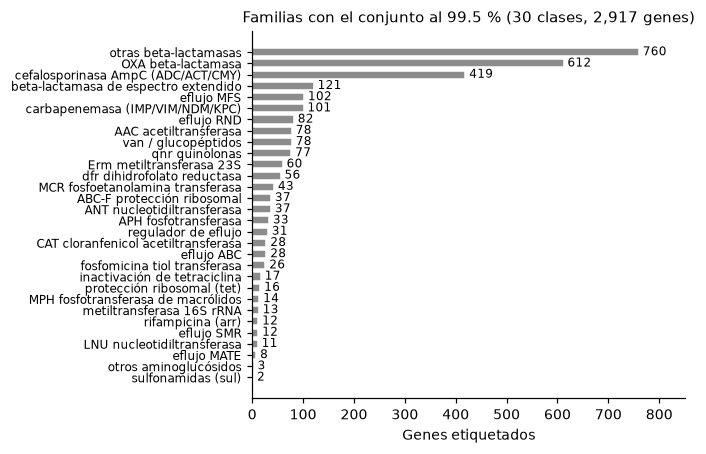

In [10]:
fig, ax = plt.subplots(figsize=(6.4, 4.2))
y = np.arange(len(cuenta_995))
ax.barh(y, cuenta_995.values, color='0.55', edgecolor='white', height=0.72)
ax.set_yticks(y); ax.set_yticklabels(cuenta_995.index, fontsize=8)
ax.invert_yaxis()
for i, n in enumerate(cuenta_995.values):
    ax.text(n + cuenta_995.max() * 0.01, i, str(n), va='center', fontsize=8)
ax.set_xlabel('Genes etiquetados')
ax.set_xlim(0, cuenta_995.max() * 1.12)
ax.set_title(f'Familias con el conjunto al 99.5 % ({len(cuenta_995)} clases, {int(cuenta_995.sum()):,} genes)', fontsize=10)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout()
fig.savefig(RES / 'familias' / f'censo_familias_id{ID}.png', dpi=200)
plt.show()

## 4. Etapa 1 — modelo binario

`reentrenar_fragmentacion.py` valida el nivel de identidad contra una lista cerrada, y
`995` todavía no está en ella. Son dos lugares:

- los valores que acepta `--identidad`
- la regla que decide si hay que filtrar el pool de positivos

Sobre lo segundo: el filtro solo puede **quitar** positivos, y sirve para bajar de nivel
(90 y 85 son subconjuntos del 95 %). Para 95, 99 y ahora 99.5, el FASTA de `POS` ya
contiene exactamente el conjunto de ese nivel, así que no hay que filtrar nada.

La celda siguiente hace ese cambio, verifica que el archivo siga siendo Python válido y
revierte si algo sale mal. Es idempotente: correrla dos veces no hace nada la segunda.

In [11]:
import ast

RUTA = RAIZ / 'scripts' / 'reentrenar_fragmentacion.py'
orig = RUTA.read_text(encoding='utf-8')
texto, hechos = orig, []

VIEJO = 'choices=["95", "90", "85", "99"]'
NUEVO = 'choices=["95", "90", "85", "99", "995"]'
if VIEJO in texto:
    texto = texto.replace(VIEJO, NUEVO, 1); hechos.append('--identidad acepta 995')
elif '"995"' in texto:
    hechos.append('--identidad ya aceptaba 995')
else:
    raise SystemExit('no reconocí la línea de --identidad; revísala a mano')

V2 = 'elif args.identidad in ("95", "99"):'
N2 = 'elif args.identidad in ("95", "99", "995"):'
if V2 in texto:
    texto = texto.replace(V2, N2, 1); hechos.append('995 no filtra el pool')
elif N2 in texto:
    hechos.append('la regla del filtro ya contemplaba 995')
else:
    raise SystemExit('no reconocí la regla de FILTRO; revísala a mano')

if texto != orig:
    ast.parse(texto)          # si no compila, lanza y no se escribe nada
    RUTA.write_text(texto, encoding='utf-8')
for h in hechos:
    print(' ', h)

  --identidad ya aceptaba 995
  la regla del filtro ya contemplaba 995


Nota de nomenclatura: los archivos van a salir como `argus_rf_k6_id995_v2.joblib` y
`r1k_id995_v2.csv`. La GUI construye la ruta como
`argus_rf_k6_id{IDENTIDAD_MODELO}{VERSION_MODELO}.joblib`, así que para usarla basta con
poner `IDENTIDAD_MODELO = 995`. Eso se hace al final, en la sección 9.

In [12]:
print('--- entrenamiento del modelo binario ---')
salida_bin = correr([sys.executable, 'scripts/reentrenar_fragmentacion.py',
                     '--identidad', ID, '--guardar-tsv'], mostrar=False)
i = salida_bin.find('positivos')
print(salida_bin[i:salida_bin.find('Para usarlo en la GUI', i)])

--- entrenamiento del modelo binario ---
[129 s, código 0]
positivos 7,933 | negativos 26,513  (1s)
genes del 1k+1k encontrados: 2,000 de 2,000
pool de entrenamiento: 32,446 genes (pos 6,933)

fragmentos: 68,311 de 32,024 genes  (0s)
  pos 13,979 | neg 54,332
  genes descartados por medir < 150 pb: 422  (pos 0)
  largo de fragmento: min 150 | mediana 500 | max 500 | de 500 pb: 44,440 (65.1 %)
  dataset escrito: dataset_fragmentado_v2_min150.tsv

train 61,479 frag (28,820 genes) | test 6,832 (3,204) con proporción natural
submuestreo 1:1 -> 25,162 fragmentos (razón original neg:pos 3.9)

X_train (25162, 4096) 412 MB (2s)
RandomForest entrenado en 21s

TEST interno, fragmento: recall=0.773  precision=0.897  f1=0.830  auc=0.947
TEST interno, gen       : recall=0.817  precision=0.848  f1=0.832  auc=0.956

1k+1k (nivel gen, regla: algún fragmento >= 0.5)
  recall=0.625  precision=0.947  f1=0.753  auc=0.912

                  Predijo NO ARG   Predijo ARG
  Real NO ARG (0)           942      

La bandera `--guardar-tsv` regenera `data/interim/dataset_fragmentado_v2_min150.tsv`,
que es el archivo que leen los notebooks de la etapa 1.

> Cuidado: ese archivo queda ahora con los datos del 99.5 %. Si se vuelve a ejecutar
> `02_rf_k6_undersampling.ipynb`, va a entrenar con este conjunto aunque sus salidas se
> llamen `comparacion_id95`. Ya pasó una vez.

## 5. Control de contaminación

El script excluye del entrenamiento los genes del conjunto de evaluación **por
identificador**, y una variante alélica tiene identificador distinto. A 99.5 % de
identidad con cobertura exigente se conservan todavía más variantes, así que este control
importa más que en la corrida anterior, no menos.

`cd-hit-est-2d` compara el conjunto nuevo contra el 1k+1k y deja las secuencias que
**no** tienen pariente cercano ahí.

In [13]:
LIMPIO = INTER / f'positivo_id{ID}_sin_parientes.fasta'
cmd = ['cd-hit-est-2d',
       '-i',  str(INTER / 'muestra_genes_completos.fasta'),
       '-i2', str(PROC / 'argdb_POSITIVO_final.fasta'),
       '-o',  str(LIMPIO),
       '-c', '0.95', '-aS', '0.90', '-n', '9', '-d', '0', '-M', '6000', '-T', '10']
_ = correr(cmd, cola=6)

n_limpio = contar(LIMPIO)
print(f'\ncon pariente en el 1k+1k : {n_995 - n_limpio:,} de {n_995:,} ({100*(n_995-n_limpio)/n_995:.0f} %)')
print(f'sin pariente              : {n_limpio:,}')

7933 compared	2400 clustered
writing non-redundant sequences from db2
writing clustering information
program completed !

Total CPU time 3.93
[2 s, código 0]

con pariente en el 1k+1k : 2,400 de 7,933 (30 %)
sin pariente              : 5,533


Las dos celdas siguientes entrenan el modelo binario otra vez, dos veces más. No es un
error: `reentrenar_fragmentacion.py` escribe siempre en el mismo nombre de archivo, que
solo depende de `--identidad`. Así que primero se entrena el control, se apartan sus
salidas con otro nombre, y al final se vuelve a entrenar el de producción para que sea el
último en quedar escrito y nada pueda pisarlo después. Es un minuto extra a cambio de no
terminar con un modelo de control guardado bajo el nombre del de producción.

In [14]:
print('--- modelo de control: solo las secuencias sin parientes ---')
salida_ctrl = correr([sys.executable, 'scripts/reentrenar_fragmentacion.py',
                      '--identidad', ID, '--filtro', str(LIMPIO)], mostrar=False)
i = salida_ctrl.find('1k+1k')
print(salida_ctrl[i:salida_ctrl.find('Guardado:', i)])

# apartar las salidas para que no las pise nada
for src, dst in [(MOD / f'argus_rf_k6_id{ID}_v2.joblib',
                  MOD / f'argus_rf_k6_id{ID}_sinparientes.joblib'),
                 (RES / f'r1k_id{ID}_v2.csv', RES / f'r1k_id{ID}_sinparientes.csv')]:
    if src.exists():
        shutil.move(str(src), str(dst)); print('->', dst.name)

--- modelo de control: solo las secuencias sin parientes ---
[121 s, código 0]
1k+1k encontrados: 2,000 de 2,000
filtro de identidad 995 %: 1,400 positivos fuera del set reducido
pool de entrenamiento: 31,046 genes (pos 5,533)

fragmentos: 65,398 de 30,624 genes  (0s)
  pos 11,066 | neg 54,332
  genes descartados por medir < 150 pb: 422  (pos 0)
  largo de fragmento: min 150 | mediana 500 | max 500 | de 500 pb: 42,568 (65.1 %)

train 58,858 frag (27,561 genes) | test 6,540 (3,063) con proporción natural
submuestreo 1:1 -> 19,918 fragmentos (razón original neg:pos 4.9)

X_train (19918, 4096) 326 MB (1s)
RandomForest entrenado en 15s

TEST interno, fragmento: recall=0.768  precision=0.824  f1=0.795  auc=0.949
TEST interno, gen       : recall=0.814  precision=0.755  f1=0.784  auc=0.952

1k+1k (nivel gen, regla: algún fragmento >= 0.5)
  recall=0.636  precision=0.924  f1=0.754  auc=0.900

                  Predijo NO ARG   Predijo ARG
  Real NO ARG (0)           925            52   <- fals

In [15]:
print('--- se vuelve a entrenar con el conjunto completo (es el modelo de producción) ---')
salida_bin = correr([sys.executable, 'scripts/reentrenar_fragmentacion.py',
                     '--identidad', ID], mostrar=False)
i = salida_bin.find('1k+1k')
print(salida_bin[i:salida_bin.find('Guardado:', i)])
shutil.copy2(RES / f'r1k_id{ID}_v2.csv', RES / f'r1k_id{ID}_completo.csv')

--- se vuelve a entrenar con el conjunto completo (es el modelo de producción) ---
[106 s, código 0]
1k+1k encontrados: 2,000 de 2,000
pool de entrenamiento: 32,446 genes (pos 6,933)

fragmentos: 68,311 de 32,024 genes  (0s)
  pos 13,979 | neg 54,332
  genes descartados por medir < 150 pb: 422  (pos 0)
  largo de fragmento: min 150 | mediana 500 | max 500 | de 500 pb: 44,440 (65.1 %)

train 61,479 frag (28,820 genes) | test 6,832 (3,204) con proporción natural
submuestreo 1:1 -> 25,162 fragmentos (razón original neg:pos 3.9)

X_train (25162, 4096) 412 MB (2s)
RandomForest entrenado en 17s

TEST interno, fragmento: recall=0.773  precision=0.897  f1=0.830  auc=0.947
TEST interno, gen       : recall=0.817  precision=0.848  f1=0.832  auc=0.956

1k+1k (nivel gen, regla: algún fragmento >= 0.5)
  recall=0.625  precision=0.947  f1=0.753  auc=0.912

                  Predijo NO ARG   Predijo ARG
  Real NO ARG (0)           942            35   <- falsos positivos
  Real ARG (1)              375

PosixPath('/mnt/c/Users/r4gbi/Desktop/Proyecto_Residencias/results/r1k_id995_completo.csv')

## 6. Comparación de las tres configuraciones

Todas sobre el mismo conjunto fijo 1k+1k, que nunca entra al entrenamiento de ninguna.

In [16]:
from sklearn.metrics import (precision_recall_curve, average_precision_score,
                             roc_auc_score, classification_report, confusion_matrix)

CORRIDAS = [
    ('95 %',                 'r1k_id95_v2.csv'),
    ('99 %',                 'r1k_id99_completo.csv'),
    ('99.5 %',               f'r1k_id{ID}_completo.csv'),
    ('99.5 % sin parientes', f'r1k_id{ID}_sinparientes.csv'),
]
pred = {}
for e, a in CORRIDAS:
    p = RES / a
    if p.exists():
        pred[e] = pd.read_csv(p)
    else:
        print(f'[falta] {a}')

comun = set.intersection(*(set(d['gen'].astype(str)) for d in pred.values()))
pred = {e: d[d['gen'].astype(str).isin(comun)].reset_index(drop=True) for e, d in pred.items()}
print(f'{len(comun):,} genes comunes a las {len(pred)} corridas')

1,977 genes comunes a las 4 corridas


In [17]:
def metricas(d, umbral=0.5):
    y = d['y'].to_numpy(int); p = d['p'].to_numpy(float)
    yhat = (p >= umbral).astype(int)
    tp = int(((y==1)&(yhat==1)).sum()); fp = int(((y==0)&(yhat==1)).sum())
    fn = int(((y==1)&(yhat==0)).sum()); tn = int(((y==0)&(yhat==0)).sum())
    r = tp/(tp+fn); pr = tp/(tp+fp) if tp+fp else np.nan
    return {'recall': r, 'precisión': pr,
            'F1': 2*pr*r/(pr+r) if pr+r else np.nan,
            'especificidad': tn/(tn+fp),
            'AP': average_precision_score(y, p), 'AUC': roc_auc_score(y, p),
            'marcados': tp+fp, 'falsas alarmas': fp, 'se escapan': fn}

pd.DataFrame({e: metricas(d) for e, d in pred.items()}).T.round(3)

,recall,precisión,F1,especificidad,AP,AUC,marcados,falsas alarmas,se escapan
95 %,0.889,0.769,0.825,0.727,0.903,0.902,1156.0,267.0,111.0
99 %,0.754,0.899,0.820,0.913,0.920,0.911,839.0,85.0,246.0
99.5 %,0.625,0.947,0.753,0.964,0.924,0.912,660.0,35.0,375.0
99.5 % sin parientes,0.636,0.924,0.754,0.947,0.907,0.900,688.0,52.0,364.0


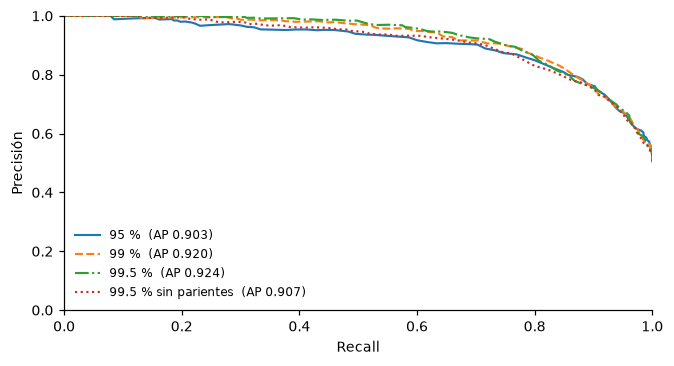

In [18]:
fig, ax = plt.subplots(figsize=(6.2, 3.4))
for (e, d), est in zip(pred.items(), ESTILOS):
    y, p = d['y'].to_numpy(int), d['p'].to_numpy(float)
    pr, rc, _ = precision_recall_curve(y, p)
    ax.plot(rc, pr, est, lw=1.4, label=f'{e}  (AP {average_precision_score(y, p):.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precisión')
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.legend(frameon=False, loc='lower left', fontsize=8)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout(); fig.savefig(RES / f'curva_pr_id{ID}.png', dpi=200); plt.show()

### Lo que hay que mirar

**El control de parientes.** Si `99.5 %` y `99.5 % sin parientes` tienen AUC distintos, la
diferencia es fuga: el modelo completo estaba entrenando con casi-copias de su propio
examen. A 0.995 de identidad eso es más probable que antes.

**Contra el 99 %.** Si las curvas van encimadas, subir la identidad otra vez no cambió la
capacidad de discriminar. Sería el mismo resultado que ya obtuvimos al pasar de 95 a 99,
y por la misma razón: el detector binario ya tenía un representante de cada grupo.

## 7. Calibración del umbral

Cada conjunto de entrenamiento produce una distribución de probabilidades distinta, así
que el 0.5 de fábrica no cae en el mismo punto de la curva. El umbral se recalibra para
cada modelo y se guarda **dentro** de su `.joblib`, no en una constante de la interfaz.

In [19]:
import joblib

obj = pred['99.5 %']
barrido = pd.DataFrame([{**{'umbral': round(t, 3)}, **metricas(obj, t)}
                        for t in np.arange(0.05, 0.96, 0.005)])
mejor = barrido.loc[barrido['F1'].idxmax()]

vista = barrido[barrido['umbral'].isin([round(x, 3) for x in np.arange(0.30, 0.71, 0.05)])]
display(vista[['umbral', 'marcados', 'falsas alarmas', 'se escapan',
               'recall', 'precisión', 'F1']].round(3).set_index('umbral'))
print(f"\nMejor F1: {mejor['F1']:.3f} en umbral {mejor['umbral']:.3f}  "
      f"(recall {mejor['recall']:.3f}, precisión {mejor['precisión']:.3f}, "
      f"{int(mejor['marcados']):,} marcados)")

,marcados,falsas alarmas,se escapan,recall,precisión,F1
umbral,,,,,,
0.30,1725,737,12,0.988,0.573,0.725
0.35,1454,493,39,0.961,0.661,0.783
0.40,1141,262,121,0.879,0.770,0.821
0.45,857,90,233,0.767,0.895,0.826
0.50,660,35,375,0.625,0.947,0.753
0.55,522,12,490,0.510,0.977,0.670
0.60,421,5,584,0.416,0.988,0.586
0.65,338,3,665,0.335,0.991,0.501
0.70,281,1,720,0.280,0.996,0.437



Mejor F1: 0.831 en umbral 0.440  (recall 0.797, precisión 0.867, 919 marcados)


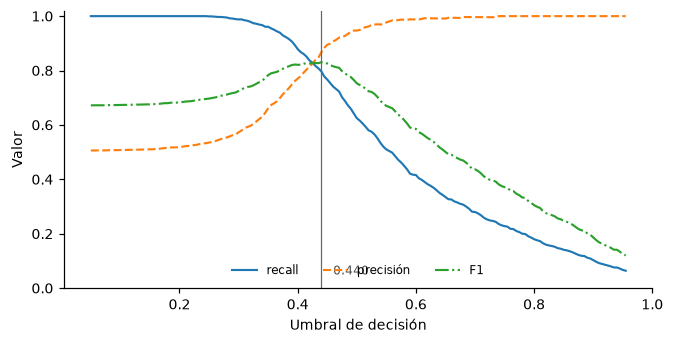

In [20]:
fig, ax = plt.subplots(figsize=(6.2, 3.2))
for col, est in zip(['recall', 'precisión', 'F1'], ESTILOS):
    ax.plot(barrido['umbral'], barrido[col], est, lw=1.4, label=col)
ax.axvline(mejor['umbral'], color='0.4', lw=0.8)
ax.annotate(f"{mejor['umbral']:.3f}", xy=(mejor['umbral'], 0.05),
            xytext=(mejor['umbral']+0.02, 0.05), fontsize=8, color='0.3')
ax.set_xlabel('Umbral de decisión'); ax.set_ylabel('Valor')
ax.set_ylim(0, 1.02); ax.legend(frameon=False, fontsize=8, ncol=3, loc='lower center')
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
fig.tight_layout(); fig.savefig(RES / f'curva_umbral_id{ID}.png', dpi=200); plt.show()

In [21]:
RUTA_MOD = MOD / f'argus_rf_k6_id{ID}_v2.joblib'
d = joblib.load(RUTA_MOD)
print('umbral que traía:', d.get('umbral'))

d['umbral'] = float(mejor['umbral'])
d['umbral_calibracion'] = (
    f"calibrado sobre el conjunto 1k+1k: maximiza F1 ({mejor['F1']:.3f}) con "
    f"recall {mejor['recall']:.3f} y precisión {mejor['precisión']:.3f}. "
    f"CD-HIT -c 0.995 -aS 0.95 -aL 0.95.")
joblib.dump(d, RUTA_MOD, compress=3)

v = joblib.load(RUTA_MOD)
print('umbral nuevo    :', v.get('umbral'))
print('justificación   :', v.get('umbral_calibracion'))

umbral que traía: 0.5
umbral nuevo    : 0.44
justificación   : calibrado sobre el conjunto 1k+1k: maximiza F1 (0.831) con recall 0.797 y precisión 0.867. CD-HIT -c 0.995 -aS 0.95 -aL 0.95.


In [22]:
print('=== reporte del modelo de producción sobre el 1k+1k ===')
y = obj['y'].to_numpy(int); p = obj['p'].to_numpy(float)
u = float(mejor['umbral'])
yhat = (p >= u).astype(int)
cm = confusion_matrix(y, yhat)
print(f'umbral {u:.3f}  |  {len(y):,} genes\n')
print(f"{'':18}{'Predijo NEG':>13}{'Predijo POS':>13}")
print(f"  {'Real NEG (0)':<16}{cm[0,0]:>13,}{cm[0,1]:>13,}")
print(f"  {'Real POS (1)':<16}{cm[1,0]:>13,}{cm[1,1]:>13,}\n")
print(classification_report(y, yhat, digits=3,
                            target_names=['no_resist (0)', 'resist (1)']))
print(f'AUC-ROC: {roc_auc_score(y, p):.3f}')

=== reporte del modelo de producción sobre el 1k+1k ===
umbral 0.440  |  1,977 genes

                    Predijo NEG  Predijo POS
  Real NEG (0)              855          122
  Real POS (1)              203          797

               precision    recall  f1-score   support

no_resist (0)      0.808     0.875     0.840       977
   resist (1)      0.867     0.797     0.831      1000

     accuracy                          0.836      1977
    macro avg      0.838     0.836     0.835      1977
 weighted avg      0.838     0.836     0.835      1977

AUC-ROC: 0.912


## 8. Resumen de las tres configuraciones

In [23]:
filas = []
for etq_, carpeta, fasta in [
    ('95 %',   'respaldo_id95', INTER / 'combinado_v4_reducido.fasta'),
    ('99 %',   'respaldo_id99', INTER / 'combinado_v4_reducido_id99.fasta'),
    ('99.5 %', None,            SALIDA),
]:
    m = (leer_json(RES / 'familias' / 'modelo_familias_meta.json') if carpeta is None
         else leer_json(RAIZ / carpeta / 'modelo_familias_meta.json'))
    clases = m.get('clases', [])
    filas.append({
        'identidad': etq_,
        'secuencias': contar(fasta),
        'genes etiquetados': m.get('n_genes'),
        'clases': len(clases) or None,
        'cajón «Otras familias»': 'sí' if 'Otras familias' in clases else 'no',
        'min_clase': m.get('min_clase'),
        'bal. acc. familias': m.get('test_gen_balanced_acc'),
    })
resumen = pd.DataFrame(filas).set_index('identidad')
resumen

,secuencias,genes etiquetados,clases,cajón «Otras familias»,min_clase,bal. acc. familias
identidad,,,,,,
95 %,4228,1380,9,sí,50,0.482908
99 %,6257,1932,17,no,30,0.721834
99.5 %,7933,2727,17,no,30,0.664216


Para que las columnas de clases se puedan comparar entre renglones hace falta que
`min_clase` sea el mismo. El censo de la sección 3 da los dos valores (50 y 30) del
conjunto nuevo, así que la comparación con el criterio viejo sale de ahí.

## 9. Etapa 2 con DNABERT  *(opcional, lento)*

Unos 30 minutos en CPU. El script no usa GPU: no tiene ninguna línea que mueva el modelo
a CUDA. Los embeddings se guardan en disco, así que una segunda corrida sobre el mismo
conjunto es mucho más rápida.

Se puede saltar en una primera pasada: el RandomForest de la sección 3 ya deja la etapa 2
funcionando.

In [24]:
CORRER_DNABERT = False      # ponlo en True cuando quieras la corrida larga

if CORRER_DNABERT:
    salida_db = correr([sys.executable, 'scripts/familias_dnabert.py'], mostrar=False)
    i = salida_db.find('--- TEST, nivel gen')
    print(salida_db[i:salida_db.find('Matriz de confusion', i)])
    j = salida_db.find('COMPARACION CONTRA EL RANDOM FOREST')
    print(salida_db[j:j+700])
else:
    print('saltada. La etapa 2 queda con el RandomForest de la sección 3.')
    print('Para usarla, pon CORRER_DNABERT = True y vuelve a ejecutar esta celda.')

saltada. La etapa 2 queda con el RandomForest de la sección 3.
Para usarla, pon CORRER_DNABERT = True y vuelve a ejecutar esta celda.


In [31]:
mdb = leer_json(RES / 'familias' / 'familias_dnabert_meta.json')
mrf = leer_json(RES / 'familias' / 'modelo_familias_meta.json')

pd.DataFrame([
    {'modelo': 'RandomForest sobre k-meros', 'clases': len(mrf.get('clases', [])),
     'balanced accuracy': mrf.get('test_gen_balanced_acc'),
     'GPU': 'no', 'entrenamiento': 'segundos'},
    {'modelo': 'DNABERT-6', 'clases': len(mdb.get('clases', [])),
     'balanced accuracy': mdb.get('test_gen_balanced_acc'),
     'GPU': 'conviene', 'entrenamiento': '~30 min en CPU'},
]).set_index('modelo')

,clases,balanced accuracy,GPU,entrenamiento
modelo,,,,
RandomForest sobre k-meros,17,0.664216,no,segundos
DNABERT-6,17,0.754273,conviene,~30 min en CPU


## 10. Dejar la interfaz apuntando al modelo nuevo

La GUI arma la ruta del modelo binario a partir de dos constantes. Cambiar `99` por `995`
es todo lo que hace falta; el umbral lo toma del propio `.joblib`.

La celda siguiente hace el cambio y lo verifica. Para regresar al modelo anterior basta
con poner `99` de vuelta: los dos archivos conviven en `data/models/`.

In [25]:
GUI = APP / 'argus_gui.py'
t = GUI.read_text(encoding='utf-8')

import re as _re
m = _re.search(r'^IDENTIDAD_MODELO = (\S+)', t, _re.M)
print('antes :', m.group(0) if m else '(no encontrado)')

if m and m.group(1) != ID:
    t = t[:m.start()] + f'IDENTIDAD_MODELO = {ID}' + t[m.end():]
    ast.parse(t)
    GUI.write_text(t, encoding='utf-8')

print('ahora :', _re.search(r'^IDENTIDAD_MODELO = \S+', GUI.read_text(encoding='utf-8'), _re.M).group(0))

ruta_esperada = MOD / f'argus_rf_k6_id{ID}_v2.joblib'
print('la GUI va a cargar:', ruta_esperada.name,
      '| existe:', ruta_esperada.exists(),
      f'| {ruta_esperada.stat().st_size/1e6:.0f} MB' if ruta_esperada.exists() else '')
print('modelo de familias:', (APP / 'modelo_familias.joblib').exists())
print('cabeza de DNABERT :', (APP / 'dnabert6_familias_cabeza.pt').exists())

antes : IDENTIDAD_MODELO = 995
ahora : IDENTIDAD_MODELO = 995
la GUI va a cargar: argus_rf_k6_id995_v2.joblib | existe: True | 18 MB
modelo de familias: True
cabeza de DNABERT : True


Con eso se puede abrir la interfaz:

```bash
python app/argus_gui.py
```

En la terminal va a imprimir qué modelo de familias cargó. El número de genes marcados
sobre el FASTA de 2,000 debe coincidir con la columna `marcados` del barrido de la
sección 7, en el renglón del umbral elegido. Si coincide, la interfaz está haciendo
exactamente lo que se midió aquí.